# 26.3 BERT Heads

Now we move from **pretraining** to the most important practical idea:

> **BERT itself is the pretrained encoder. A task-specific "head" is added on top of its representations to solve a particular downstream task.**

You already know the Transformer encoder, so think of the architecture as:

```text
                 Input text
                     │
                     ▼
                BERT Encoder
                     │
             contextual representations
                     │
          ┌──────────┼──────────┐
          ▼          ▼          ▼
      Sequence      Token       QA
       Head         Head        Head
          │          │           │
          ▼          ▼           ▼
      one label   one label    start/end
       /input      /token       positions
```

The **same pretrained BERT encoder** can therefore support very different tasks.

---

# 1. Sequence Classification

## What problem does it solve?

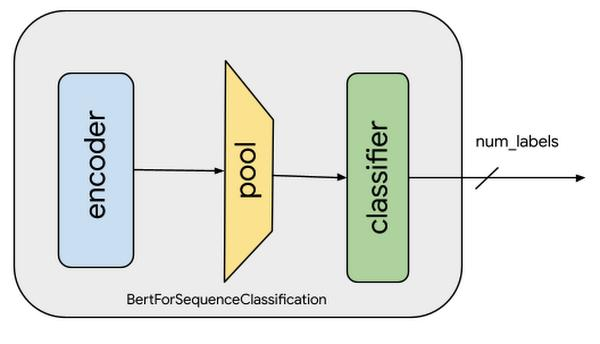

Sequence classification assigns **one label to an entire input sequence**.

Examples:

| Task | Input | Output |
|---|---|---|
| Sentiment | `"This movie is excellent"` | `Positive` |
| Spam detection | `"Congratulations, you won..."` | `Spam` |
| Topic classification | `"The stock market fell..."` | `Finance` |
| Intent classification | `"I want to cancel my order"` | `Cancel_Order` |

The key characteristic is:

> **One prediction for the whole sequence.**

---

## Architecture

Suppose:

```text
[CLS] I love this movie [SEP]
```

BERT produces:

```text
[CLS]    I    love    this    movie    [SEP]
  │      │      │       │        │        │
 h₀      h₁     h₂      h₃       h₄       h₅
```

We commonly use the contextual representation corresponding to `[CLS]`:

$$
h_{CLS} = h_0
$$

Then pass it through a classification head:

$$
z = W h_{CLS} + b
$$

and:

$$
\hat{y} = \operatorname{softmax}(z)
$$

Conceptually:

```text
                 BERT
                  │
                  ▼
        [CLS] I love this movie
                  │
                  ▼
                h_CLS
                  │
                  ▼
             Linear classifier
                  │
                  ▼
                Softmax
                  │
             ┌────┼────┐
             ▼    ▼    ▼
           Neg  Neutral Pos
```

### Example

```text
Input:
"I absolutely loved the movie."

BERT
  ↓
h_[CLS]
  ↓
Classification head
  ↓
Positive: 0.97
Negative: 0.03
```

---

# 2. Token Classification

Now the prediction changes.

Instead of:

> **one prediction for the whole sentence**

we want:

> **one prediction for each token.**

This is called **token classification**.

Common applications:

- Named Entity Recognition (NER)
- POS tagging
- token-level classification

For example:

```text
Barack Obama was born in Hawaii
```

NER might produce:

```text
Barack   → B-PER
Obama    → I-PER
was      → O
born     → O
in       → O
Hawaii   → B-LOC
```

---

## Architecture

BERT produces a representation for **every token**:

```text
             BERT
              │
              ▼
[CLS] Barack Obama was born in Hawaii [SEP]
  │      │      │    │     │     │      │
 h₀     h₁     h₂   h₃    h₄    h₅     h₆
         │      │    │     │     │
         ▼      ▼    ▼     ▼     ▼
        classifier applied independently
         │      │    │     │     │
         ▼      ▼    ▼     ▼     ▼
        B-PER  I-PER O     O     B-LOC
```

Mathematically, for each token \(i\):

$$
z_i = W h_i + b
$$

and:

$$
\hat{y}_i = \operatorname{softmax}(z_i)
$$

So instead of:

$$
h_{CLS} \rightarrow \text{one prediction}
$$

we have:

$$
h_1,h_2,\ldots,h_n
\rightarrow
y_1,y_2,\ldots,y_n
$$

---

## Sequence vs Token Classification

This distinction is **very important for interviews**.

| | Sequence Classification | Token Classification |
|---|---|---|
| Prediction | One per sequence | One per token |
| Representation | Usually `[CLS]` | Each token's hidden state |
| Example | Sentiment | NER |
| Output | `Positive` | `B-PER`, `O`, `B-LOC`, ... |

Mental shortcut:

```text
Sequence classification:

Sentence ──→ BERT ──→ [CLS] ──→ ONE label


Token classification:

Sentence ──→ BERT ──→ h₁ h₂ h₃ ... hₙ
                       ↓  ↓  ↓      ↓
                      y₁ y₂ y₃ ... yₙ
```

---

# 3. The WordPiece Complication in Token Classification

This is a practical detail you **must understand**.

BERT uses WordPiece, so one original word may become multiple subword tokens.

For example, conceptually:

```text
Washington
     ↓
Washington
```

but another word could become:

```text
playing
   ↓
play ##ing
```

Suppose your NER dataset says:

```text
playing → O
```

but the tokenizer produces:

```text
play → O
##ing → ?
```

Now we have to decide how labels align with subword tokens.

Common approaches include:

- assign the original label to the first subword and ignore subsequent subwords for loss;
- propagate the label to all subwords, depending on the task/design.

In Hugging Face token-classification workflows, `word_ids()` is commonly used to map subword tokens back to their original words and align labels appropriately.

This becomes **very important when you implement NER with BERT** later.

---

# 4. Question Answering

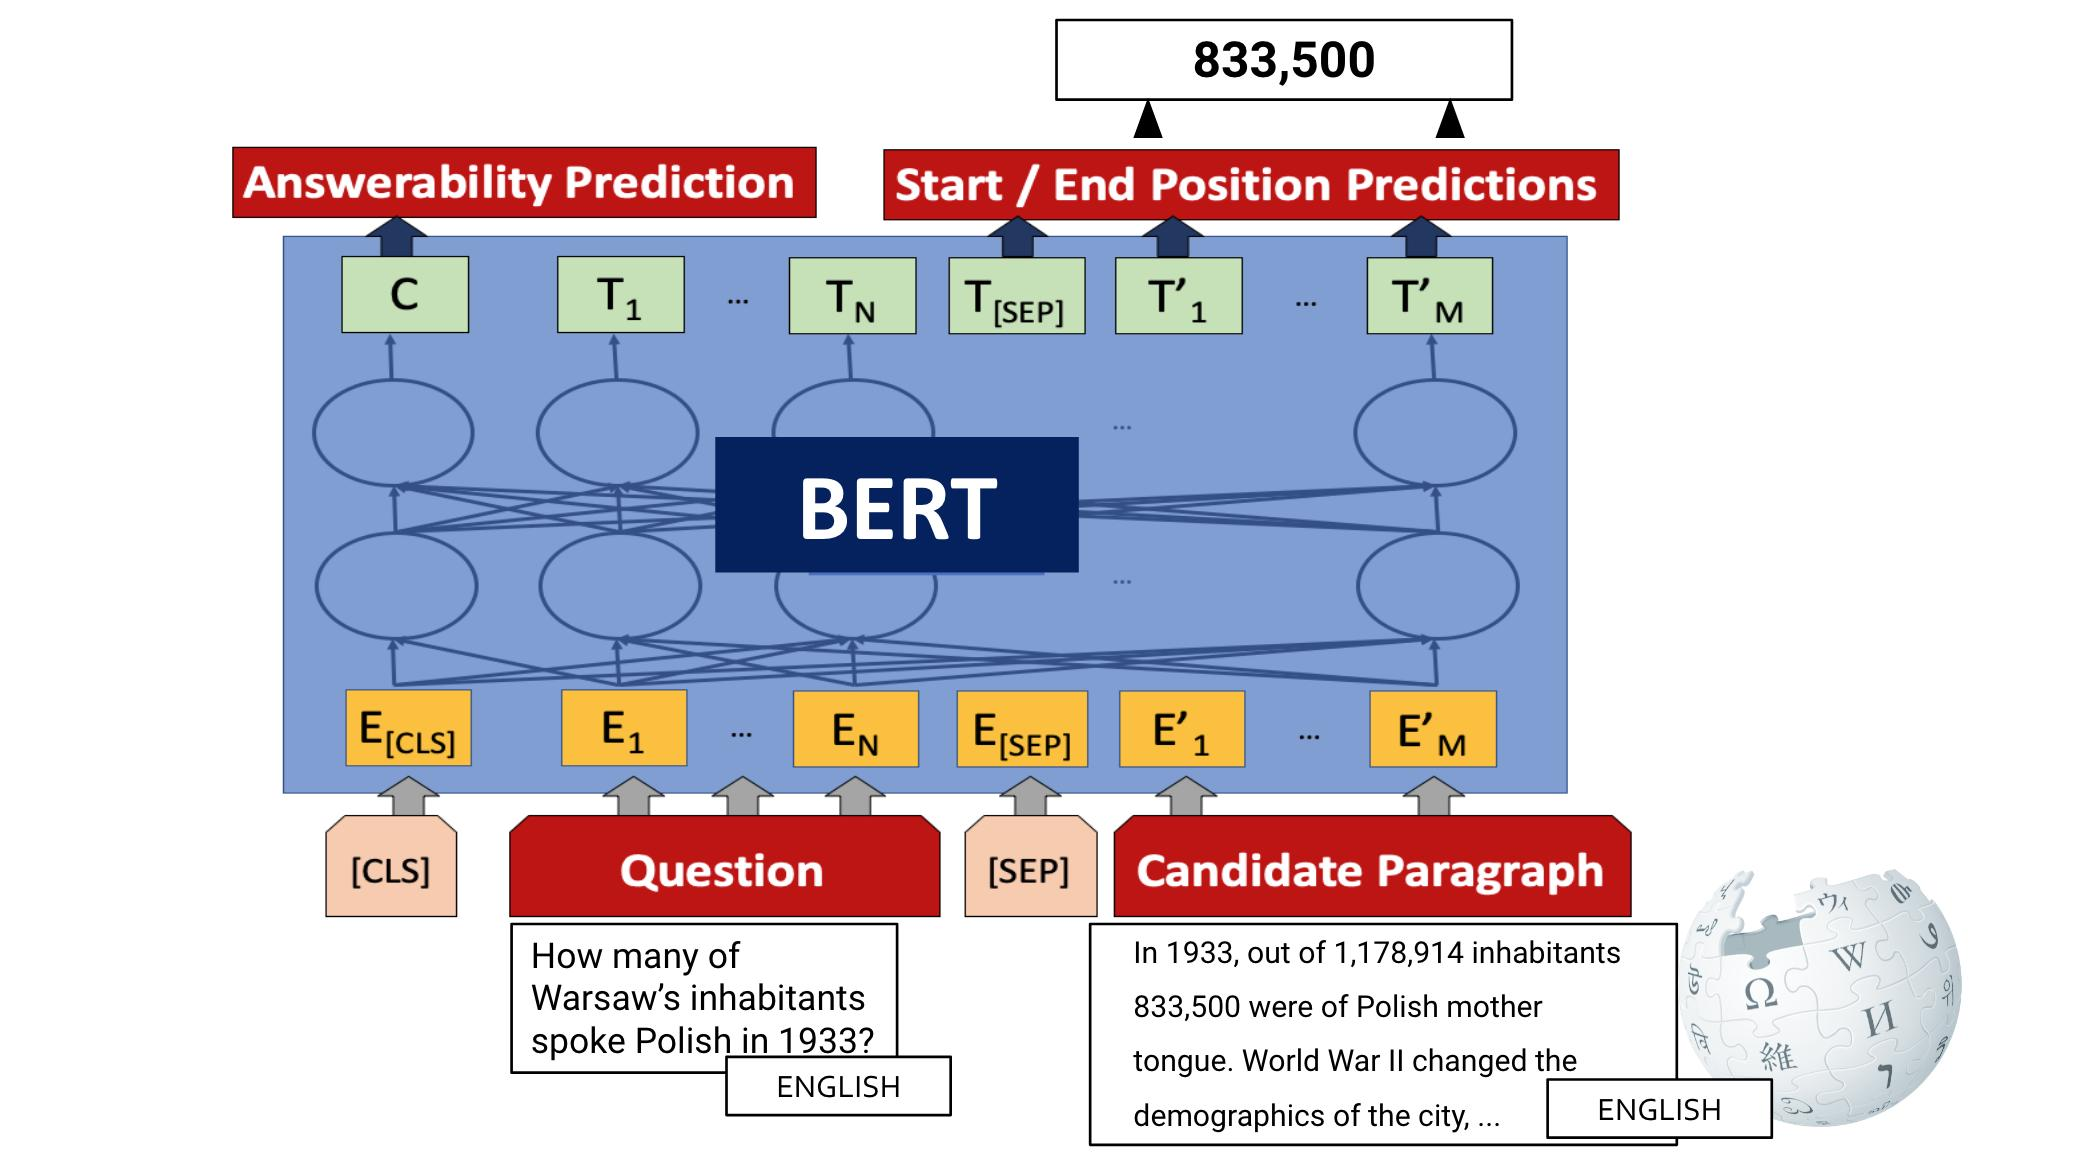

Now we have a more interesting head.

BERT can be used for **extractive question answering**.

The model receives:

```text
Question + Context
```

and must identify the answer as a **span inside the context**.

Example:

### Context

> Paris is the capital of France.

### Question

> What is the capital of France?

Expected answer:

> **Paris**

---

## Input

BERT can represent the pair approximately as:

```text
[CLS]
What is the capital of France?
[SEP]
Paris is the capital of France.
[SEP]
```

Conceptually:

```text
        Question
           │
           ▼
[CLS] What is ... [SEP]
           │
           +
        Context
           │
           ▼
Paris is the capital of France [SEP]
           │
           ▼
          BERT
           │
           ▼
   contextual representation
        for each token
```

---

# 5. Start and End Positions

The key idea:

> **Predict where the answer starts and where it ends.**

Suppose:

```text
Context:

Paris is the capital of France.
  ↑
start
```

The model produces two distributions:

### Start-position probabilities

$$
P(start=i)
$$

### End-position probabilities

$$
P(end=j)
$$

So:

```text
BERT
 │
 ├───────────────┐
 ▼               ▼
Start head       End head
 │               │
 ▼               ▼
P(start=i)       P(end=j)
```

For example:

```text
Context tokens:

Paris   is   the   capital   of   France
  ↑
  └── start = 0


Paris   is   the   capital   of   France
  ↑
  └── end = 0
```

Therefore:

```text
Answer = tokens[start : end]
```

For a multi-token answer:

```text
The capital of France is Paris

             ↑             ↑
           start          end
```

The model could predict:

```text
start = 3
end   = 5
```

giving:

```text
capital of France
```

---

# 6. Mathematical View of QA

Let the BERT hidden representation for token \(i\) be:

$$
h_i \in \mathbb{R}^d
$$

We have two learned vectors:

$$
w_s, w_e \in \mathbb{R}^d
$$

Then:

$$
s_i = w_s^T h_i
$$

$$
e_i = w_e^T h_i
$$

Apply softmax:

$$
P(start=i)
=
\frac{e^{s_i}}
{\sum_j e^{s_j}}
$$

and:

$$
P(end=i)
=
\frac{e^{e_i}}
{\sum_j e^{e_j}}
$$

The model therefore learns:

```text
Every token
    │
    ├──→ How likely is this the START?
    │
    └──→ How likely is this the END?
```

During training, the loss is typically the sum of the start-position and end-position cross-entropies:

$$
\boxed{
\mathcal{L}_{QA}
=
\mathcal{L}_{start}
+
\mathcal{L}_{end}
}
$$

---

# 7. Why BERT Works Well for QA

Remember what you learned about contextual representations.

Consider:

```text
Paris is the capital of France.
```

The representation of `"Paris"` is influenced by:

```text
capital
France
```

through self-attention.

Therefore BERT can learn relationships such as:

```text
Question:
"What is the capital of France?"

             ↕ attention

Context:
"Paris is the capital of France."
```

The answer token's representation becomes highly informed by the question.

This is one of the major strengths of using an encoder for extractive QA.

---

# 8. Three Heads — One Encoder

This is the most important mental model from this section.

```text
                         ┌──────────────────────┐
                         │    PRETRAINED BERT   │
                         │      ENCODER         │
                         └──────────┬───────────┘
                                    │
                      contextual token representations
                                    │
               ┌─────────────────────┼─────────────────────┐
               │                     │                     │
               ▼                     ▼                     ▼
        Sequence Head          Token Head              QA Head
               │                     │                     │
               ▼                     ▼              ┌──────┴──────┐
         [CLS] → label          each token → label  start        end
               │                     │              │             │
               ▼                     ▼              └──────┬──────┘
         Sentiment/Intent           NER                    ▼
                                                       Answer span
```

This is the **transfer learning** idea:

$$
\boxed{
\text{Pretrained BERT}
+
\text{Task-specific head}
\rightarrow
\text{Downstream model}
}
$$

The encoder contains general language knowledge, while the head converts those representations into the required output format.

---

# 9. Hugging Face Mental Mapping

You don't need to implement this yet, but you should recognize the model names when we reach the practical module.

Conceptually:

| Task | Hugging Face model | Output |
|---|---|---|
| Sequence classification | `BertForSequenceClassification` | class logits |
| Token classification | `BertForTokenClassification` | token logits |
| Extractive QA | `BertForQuestionAnswering` | start + end logits |

The important thing isn't memorizing class names.

Understand the architecture:

```text
BertForSequenceClassification
       ↓
BERT
       ↓
CLS representation
       ↓
Classifier


BertForTokenClassification
       ↓
BERT
       ↓
all token representations
       ↓
Token classifier


BertForQuestionAnswering
       ↓
BERT
       ↓
all token representations
       ↓
start + end classifiers
```

---

# 10. Common Mistakes ⚠️

### ❌ "All BERT tasks use `[CLS]`."

No.

`[CLS]` is especially useful for **sequence-level** tasks.

Token classification needs the representations of individual tokens.

QA needs representations across the input sequence to predict start/end positions.

---

### ❌ "Token classification means one label for every word."

Not necessarily.

BERT operates on **tokens/subwords**, not necessarily original words.

This is why WordPiece → label alignment matters.

---

### ❌ "Question answering predicts the answer text directly."

For **extractive QA**, BERT typically predicts **start and end positions**, from which the answer span is extracted.

That's different from generative QA.

---

### ❌ "The head contains all the intelligence."

No.

The head is usually relatively small.

A large amount of the useful linguistic representation comes from the pretrained encoder.

---

# Must Know 🔴

You should be able to explain:

- What a task-specific BERT head is.
- Sequence classification → one prediction per sequence.
- Token classification → one prediction per token.
- QA → predict answer start and end positions.
- Why `[CLS]` is useful for sequence classification.
- Why token classification uses all relevant token representations.
- Why QA needs token-level representations.
- The difference between extractive and generative QA.
- WordPiece/subword label alignment for token classification.

# Good to Know 🟡

- Classification-head equations.
- Start/end logits.
- QA loss = start loss + end loss.
- Hugging Face's three corresponding model classes.
- Why contextual representations make QA possible.

---

## 🧠 The Interview-Level Mental Model

If someone asks:

> **"How can the same BERT model perform classification, NER, and QA?"**

Your answer should be:

> **BERT provides contextualized representations for the input tokens. For sequence classification, we use a sequence-level representation such as `[CLS]` and add a classifier. For token classification, we apply a classifier to each token's contextual representation. For extractive question answering, we apply separate start and end prediction heads over the token representations to identify the answer span. The encoder is largely shared; the task-specific head changes according to the output structure.**

---